# Chapter 8: Production ML / MLOps Vocabulary

**Aventum Round 1 prep · STRATEGY.md §5.6** · Time needed: about 75 minutes

This is the chapter closest to your real experience (FastAPI, Docker, CI/CD at HDFC). The aim is to add the **model-specific** layer on top: drift, delayed labels, calibration, reason codes, versioning and the PyTorch loop, so you can talk about the whole lifecycle fluently.

### Syllabus
| No. | Topic | Interview use |
|---|---|---|
| 8.1 | Data drift: PSI and the KS test | "How would you monitor the model?" |
| 8.2 | Delayed labels (insurance losses arrive months later) | "How do you monitor when labels arrive months later?" |
| 8.3 | Calibration: reliability curves, Platt / isotonic | "Can the business trust the probability?" |
| 8.4 | Explainability: reason codes, permutation importance, the link to SHAP | "How would an underwriter know why?" |
| 8.5 | Versioning and a model registry (MLflow concepts) | "How do you manage the model lifecycle?" |
| 8.6 | PyTorch basics recap and a serving sketch | "A light technical question" |

## 0. Setup

In [1]:
import json, hashlib, tempfile, os
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
import joblib
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.inspection import permutation_importance
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42); torch.manual_seed(42)
print("Ready")

Ready


---
## 8.1 Data Drift

### Theory
**Data drift** = the distribution of the model's **inputs** changes after deployment (new brokers, a market hardening, a new line of business). **Concept drift** = the relationship between inputs and outcome changes (the same risk now behaves differently). You can detect data drift **immediately**; concept drift needs labels (§8.2).

### Population Stability Index (PSI)
Bin the feature using the **reference** (training) distribution, then compare the share of the reference ($e_i$) and of the current data ($a_i$) in each bin:
$$\boxed{\text{PSI} = \sum_i (a_i - e_i)\,\ln\frac{a_i}{e_i}}$$

| PSI | Reading |
|---|---|
| < 0.1 | Stable |
| 0.1 to 0.25 | Moderate shift: investigate |
| > 0.25 | Major shift: act (retrain or review) |

**Kolmogorov–Smirnov test:** $D = \max_x |F_{ref}(x) - F_{cur}(x)|$, the biggest gap between the two cumulative distributions. Beware: with large samples, even trivial shifts give tiny p-values, so **look at the size of D, not just p**.

### Solved Example 8.1
**Q.** Premium bands at training: 25% in each of 4 bins. This month: 10%, 20%, 30%, 40%. Find the PSI.

**Solution.**
| Bin | $e$ | $a$ | $a - e$ | $\ln(a/e)$ | product |
|---|---|---|---|---|---|
| 1 | 0.25 | 0.10 | −0.15 | ln 0.4 = −0.9163 | 0.1374 |
| 2 | 0.25 | 0.20 | −0.05 | ln 0.8 = −0.2231 | 0.0112 |
| 3 | 0.25 | 0.30 | +0.05 | ln 1.2 = 0.1823 | 0.0091 |
| 4 | 0.25 | 0.40 | +0.15 | ln 1.6 = 0.4700 | 0.0705 |

PSI = 0.1374 + 0.0112 + 0.0091 + 0.0705 = **0.228**

**Ans.** Moderate shift: the book is moving towards bigger risks. Investigate before trusting the model on the new mix.

> **Note:** every product is ≥ 0 (when $a > e$ the log is positive; when $a < e$ both factors are negative), so PSI can't cancel out. Bins with 0% break the log, so add a small epsilon.

In [2]:
def psi(ref, cur, bins=10, eps=1e-4):
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(ref, edges)[0] / len(ref) + eps
    a = np.histogram(cur, edges)[0] / len(cur) + eps
    return np.sum((a - e) * np.log(a / e))

e = np.array([0.25] * 4); a = np.array([0.10, 0.20, 0.30, 0.40])
print("Solved Example 8.1 PSI =", round(np.sum((a - e) * np.log(a / e)), 4))

Solved Example 8.1 PSI = 0.2282


#### Program 8.1: monitor a feature month by month

In [3]:
rng = np.random.default_rng(0)
ref = rng.lognormal(np.log(60), 0.6, 20000)                      # training-time premiums
months = pd.period_range("2026-01", periods=9, freq="M")
rows = []
for k, m in enumerate(months):
    shift = 0.0 if k < 4 else 0.06 * (k - 3)                     # the book drifts upward from May
    cur = rng.lognormal(np.log(60) + shift, 0.6, 3000)
    D, p = stats.ks_2samp(ref, cur)
    rows.append(dict(month=str(m), PSI=psi(ref, cur), KS_D=D, KS_p=p))
mon = pd.DataFrame(rows)
mon["status"] = pd.cut(mon.PSI, [-1, 0.1, 0.25, 99], labels=["stable", "investigate", "ACT"])
mon.round(4)

,month,PSI,KS_D,KS_p,status
0,2026-01,0.0037,0.0177,0.3838,stable
1,2026-02,0.0030,0.0140,0.6777,stable
2,2026-03,0.0020,0.0152,0.5762,stable
3,2026-04,0.0031,0.0217,0.1707,stable
4,2026-05,0.0206,0.0622,0.0000,stable
5,2026-06,0.0357,0.0797,0.0000,stable
6,2026-07,0.0823,0.1246,0.0000,stable
7,2026-08,0.1499,0.1603,0.0000,investigate
8,2026-09,0.2191,0.1878,0.0000,investigate


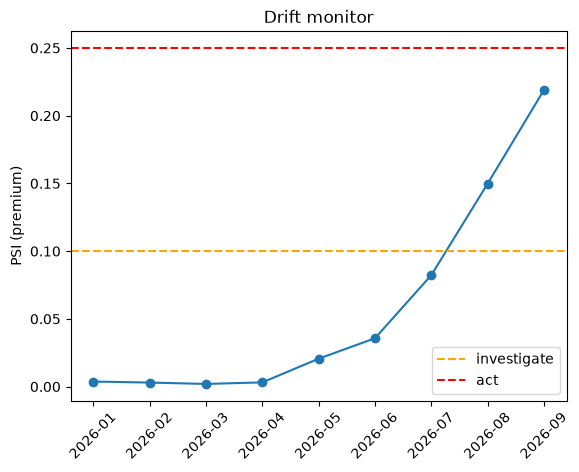

In [4]:
plt.plot(mon.month, mon.PSI, "o-")
plt.axhline(0.1, color="orange", ls="--", label="investigate"); plt.axhline(0.25, color="red", ls="--", label="act")
plt.xticks(rotation=45); plt.ylabel("PSI (premium)"); plt.legend(); plt.title("Drift monitor"); plt.show()

Note how the KS p-value turns tiny from the first month of drift, while PSI says "investigate" only once the shift is material. **For alerting, use effect-size thresholds (PSI, D), not p-values.**

---
## 8.2 Delayed Labels

In insurance the label (did this policy have a loss? how big?) arrives **months or years** after the decision. Long-tail lines can take 5+ years to develop. So "monitor accuracy" can't mean "check AUC every day".

**What to monitor at each horizon:**
| Horizon | Signal | Example |
|---|---|---|
| Real time | Input drift (PSI), data quality, latency, errors | Missing fields, new categories |
| Days | **Prediction drift**: the distribution of scores | Mean P(bind) jumps from 0.38 to 0.50 |
| Weeks | **Proxy / early labels** | Bind/NTU (fast), first notification of loss |
| Months to years | **True performance by vintage** | AUC and calibration per underwriting month, once labels have matured |

**Solved Example 8.2.** A model went live in January. By October, which months can you evaluate on 6-month loss development? **Ans.** January to April only (April + 6 months = October). May to September are still immature. **Always report performance by vintage with its maturity**, never a single pooled number that mixes mature and immature months.

In [5]:
live = pd.period_range("2026-01", "2026-09", freq="M"); today = pd.Period("2026-10", freq="M")
pd.DataFrame({"underwriting month": live.astype(str),
              "months developed": [(today - m).n for m in live],
              "evaluable at 6m maturity?": [(today - m).n >= 6 for m in live]})

,underwriting month,months developed,evaluable at 6m maturity?
0,2026-01,9,True
1,2026-02,8,True
2,2026-03,7,True
3,2026-04,6,True
4,2026-05,5,False
5,2026-06,4,False
6,2026-07,3,False
7,2026-08,2,False
8,2026-09,1,False


---
## 8.3 Calibration

### Theory
A model is **calibrated** if, among cases scored $p$, a fraction $p$ are positive. **Boosted trees and neural nets are often over- or under-confident**, while logistic regression is usually close. A decision rule ("auto-refer if P(loss) > 0.3") or an expected-value calculation (premium × P(bind)) needs calibrated numbers.

**Brier score** $= \frac1n \sum (p_i - y_i)^2$ (lower is better). It rewards both ranking and calibration.

**Fixes** (fitted on a held-out calibration set):
- **Platt scaling**: fit a logistic regression on the score. Smooth, needs little data.
- **Isotonic regression**: a monotone step function. Flexible, needs more data.

### Solved Example 8.3
**Q.** Predictions [0.9, 0.2, 0.6], outcomes [1, 0, 0]. Find the Brier score.

**Solution.** $(0.9-1)^2 + (0.2-0)^2 + (0.6-0)^2 = 0.01 + 0.04 + 0.36 = 0.41$, and $0.41/3 = $ **0.137**. The third case (0.6 for a negative) contributes most.

In [6]:
print("Brier =", round(brier_score_loss([1, 0, 0], [0.9, 0.2, 0.6]), 4))

rng = np.random.default_rng(1)
n = 12000
X = rng.normal(size=(n, 6))
logit = -1.5 + X[:, 0] - 0.8 * X[:, 1] + 0.6 * X[:, 2] * X[:, 3]
y = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
Xtr, ytr, Xcal, ycal, Xte, yte = X[:6000], y[:6000], X[6000:9000], y[6000:9000], X[9000:], y[9000:]

gbm = GradientBoostingClassifier(n_estimators=400, max_depth=4, learning_rate=0.2, random_state=0).fit(Xtr, ytr)
iso = IsotonicRegression(out_of_bounds="clip").fit(gbm.predict_proba(Xcal)[:, 1], ycal)   # fitted on the CALIBRATION set

p_raw = gbm.predict_proba(Xte)[:, 1]
p_cal = iso.predict(p_raw)
for name, p in [("GBM raw", p_raw), ("GBM + isotonic", p_cal)]:
    print(f"{name:15s} AUC {roc_auc_score(yte, p):.3f}  Brier {brier_score_loss(yte, p):.4f}")

Brier = 0.1367


GBM raw         AUC 0.761  Brier 0.1626
GBM + isotonic  AUC 0.759  Brier 0.1543


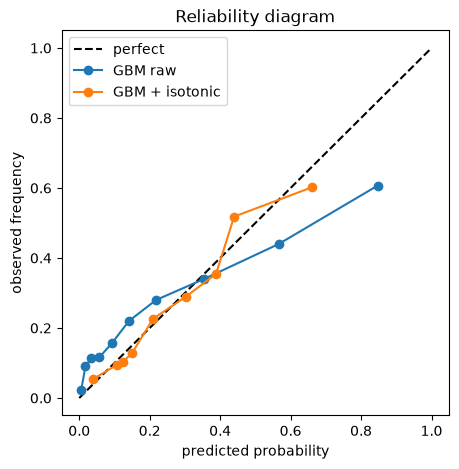

In [7]:
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfect")
for name, p in [("GBM raw", p_raw), ("GBM + isotonic", p_cal)]:
    fp, mp = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    plt.plot(mp, fp, "o-", label=name)
plt.xlabel("predicted probability"); plt.ylabel("observed frequency"); plt.legend(); plt.title("Reliability diagram"); plt.show()

#### Explanation
- The deliberately over-fitted GBM is **over-confident**: its points sit off the diagonal at the extremes.
- Isotonic calibration, fitted on a **separate** calibration set (never the training set), pulls it back to the diagonal. AUC stays about the same (isotonic is monotone, so the ranking barely changes) while the Brier score improves.
- In sklearn you can wrap this as `CalibratedClassifierCV(model, method="isotonic")`. It's done by hand here so each step is visible.

---
## 8.4 Explainability: Reason Codes

For regulated or consequential decisions, an underwriter needs **why**, not just a score. Keep an audit trail of the inputs, the model version, the score and the reasons.

### Reason codes from a linear model
For logistic regression, the contribution of feature $j$ for one case, relative to an average case, is:
$$\boxed{c_j = \beta_j\,(x_j - \bar x_j)}$$
Sort by $|c_j|$ and report the top 3 as reason codes. **For linear models these are exactly the SHAP values** (with independent features), so it's a good bridge to the SHAP question.

### Solved Example 8.4
**Q.** A P(loss) model has $\beta$ = {prior_claims: 0.8, tier_A: −0.5, log_premium: 0.3}. The book averages are {1.0, 0.3, 11.0}. A submission has {3, 0, 12}. Give the reason codes.

**Solution.**
- prior_claims: 0.8 × (3 − 1.0) = **+1.60**
- tier_A: −0.5 × (0 − 0.3) = **+0.15** (not a tier-A broker, so it loses the discount)
- log_premium: 0.3 × (12 − 11) = **+0.30**

**Ans.** Top reasons: (1) prior claims well above average, (2) larger than average premium, (3) non-tier-A broker. All of them push the risk **up**.

In [8]:
beta = {"prior_claims": 0.8, "tier_A": -0.5, "log_premium": 0.3}
avg  = {"prior_claims": 1.0, "tier_A": 0.3, "log_premium": 11.0}
x    = {"prior_claims": 3,   "tier_A": 0,   "log_premium": 12}
contrib = {k: beta[k] * (x[k] - avg[k]) for k in beta}
print(sorted(contrib.items(), key=lambda kv: -abs(kv[1])))

[('prior_claims', 1.6), ('log_premium', 0.3), ('tier_A', 0.15)]


#### Program 8.2: global importance with permutation importance
**Permutation importance:** shuffle one feature on the test set and measure how much the score drops. It works for any model.

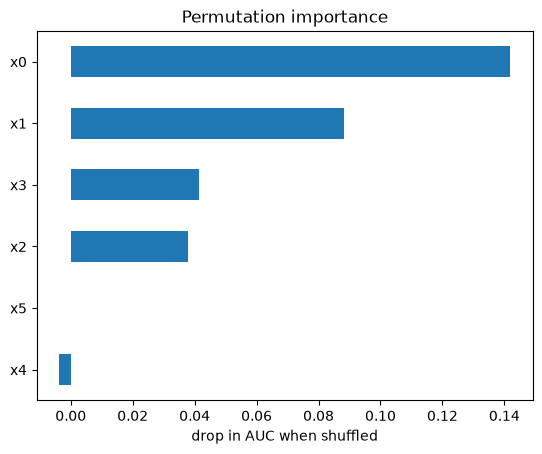

In [9]:
pi = permutation_importance(gbm, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=[f"x{j}" for j in range(6)]).sort_values()
imp.plot(kind="barh"); plt.xlabel("drop in AUC when shuffled"); plt.title("Permutation importance"); plt.show()

x0 and x1 (main effects), and x2 and x3 (an interaction), matter; x4 and x5 are noise. That matches how we built the data. **SHAP** (`shap` library, TreeExplainer) gives per-case contributions for tree models. Mention it, but the linear case above is the one to be able to explain from first principles.

---
## 8.5 Versioning and a Model Registry

**Reproducibility rule:** a prediction must be traceable to the **exact** data version + code version + model artefact + config (and, for GenAI, the **prompt version**, which your HDFC prompts-in-Git habit already covered).

A **model registry** (MLflow is the common one) stores each trained model with its metrics and lineage, and moves it through **stages**: None → Staging → Production → Archived. Serving loads "the Production version", so promotion and rollback become a metadata change, not a redeploy.

#### Program 8.3: a minimal registry (to understand what MLflow does for you)

In [10]:
reg_dir = tempfile.mkdtemp(prefix="registry_")         # temp folder, nothing written into the repo

def sha(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()[:12]

def register(model, name, train_X, metrics, code_version, stage="Staging"):
    path = os.path.join(reg_dir, f"{name}.joblib"); joblib.dump(model, path)
    entry = {"name": name, "model_sha": sha(open(path, "rb").read()), "data_sha": sha(np.ascontiguousarray(train_X).tobytes()),
             "code_version": code_version, "metrics": metrics, "stage": stage}
    reg_file = os.path.join(reg_dir, "registry.json")
    reg = json.load(open(reg_file)) if os.path.exists(reg_file) else []
    reg.append(entry); json.dump(reg, open(reg_file, "w"), indent=2)
    return entry

register(gbm, "bind_model_v1", Xtr, {"auc": round(roc_auc_score(yte, p_raw), 3), "brier": round(brier_score_loss(yte, p_raw), 4)}, "git:abc123")
register(iso, "bind_calibrator_v1", Xcal, {"brier_after": round(brier_score_loss(yte, p_cal), 4)}, "git:abc123")
print(open(os.path.join(reg_dir, "registry.json")).read())

[
  {
    "name": "bind_model_v1",
    "model_sha": "6bcd59ff0478",
    "data_sha": "459f2bc5e52c",
    "code_version": "git:abc123",
    "metrics": {
      "auc": 0.761,
      "brier": 0.1626
    },
    "stage": "Staging"
  },
  {
    "name": "bind_calibrator_v1",
    "model_sha": "396afe9c19ba",
    "data_sha": "f76f65ff048c",
    "code_version": "git:abc123",
    "metrics": {
      "brier_after": 0.1543
    },
    "stage": "Staging"
  }
]


**The same in MLflow** (not run here; for reference):
```python
import mlflow
with mlflow.start_run():
    mlflow.log_params({"max_depth": 4, "n_estimators": 400})
    mlflow.log_metrics({"auc": auc, "brier": brier})
    mlflow.sklearn.log_model(gbm, "model", registered_model_name="bind_model")
# later: load whatever is currently in Production
model = mlflow.pyfunc.load_model("models:/bind_model@production")
```

---
## 8.6 PyTorch Basics Recap and a Serving Sketch

In [11]:
Xt = torch.tensor(Xtr, dtype=torch.float32); yt = torch.tensor(ytr, dtype=torch.float32)
dl = DataLoader(TensorDataset(Xt, yt), batch_size=256, shuffle=True)

net = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, 1))   # outputs a logit
loss_fn = nn.BCEWithLogitsLoss()                                     # sigmoid + log-loss in one, numerically stable
opt = torch.optim.Adam(net.parameters(), lr=1e-2)

for epoch in range(15):
    net.train()
    for xb, yb in dl:
        loss = loss_fn(net(xb).squeeze(1), yb)
        opt.zero_grad(); loss.backward(); opt.step()

net.eval()
with torch.no_grad():
    p_nn = torch.sigmoid(net(torch.tensor(Xte, dtype=torch.float32))).squeeze(1).numpy()
print(f"MLP  AUC {roc_auc_score(yte, p_nn):.3f}  Brier {brier_score_loss(yte, p_nn):.4f}")

path = os.path.join(reg_dir, "mlp.pt"); torch.save(net.state_dict(), path)      # save WEIGHTS, not the object
net2 = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, 1)); net2.load_state_dict(torch.load(path))
print("reloaded model identical:", all(torch.equal(a, b) for a, b in zip(net.state_dict().values(), net2.state_dict().values())))

MLP  AUC 0.806  Brier 0.1382
reloaded model identical: True


#### Explanation (the checklist)
| Step | Code |
|---|---|
| Data | `TensorDataset` / custom `Dataset` → `DataLoader(batch_size, shuffle=True)` |
| Model | `nn.Module` / `nn.Sequential`; output **logits** |
| Loss | `BCEWithLogitsLoss` (binary), `CrossEntropyLoss` (multi-class), both on logits |
| Step | forward → loss → `zero_grad()` → `backward()` → `step()` |
| Inference | `model.eval()` + `torch.no_grad()` |
| Save | `torch.save(model.state_dict(), path)`; to load, rebuild the class and call `load_state_dict` |

### Serving sketch (your HDFC pattern + model-specific additions)
```python
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()
MODEL_VERSION = "bind_model:3"                    # resolved from the registry at startup

class Submission(BaseModel):
    prior_claims: int
    tier: str
    log_premium: float

@app.post("/score")
def score(s: Submission):
    p = calibrator(model(s))                      # calibrated probability
    reasons = top_reason_codes(s, k=3)            # §8.4
    log_prediction(s, p, reasons, MODEL_VERSION)  # for monitoring, OPE, and audit (§8.1, Ch 6)
    return {"p_bind": p, "reasons": reasons, "model_version": MODEL_VERSION}
```
**What's new compared with a standard microservice:** a calibrated output, reason codes, the model version in every response, and **prediction logging** (inputs, output, version, and the propensity if the score drives a choice). Monitoring, audit and off-policy evaluation all depend on that log.

---
## Exercise 8.1
1. Reference bins 50% / 50%, current 70% / 30%. Compute the PSI and classify it.
2. KS test on 200,000 rows gives p = 1e-12 but D = 0.004. Alert?
3. A model went live in March. Today is November. With 9-month loss development, which months are evaluable?
4. Why must the calibrator be fitted on data the model wasn't trained on?
5. Reason codes: β = {claims: 0.5}, average claims 2, this risk has 0 claims. What is the contribution? Is it a reason the risk looks better or worse?
6. Why `BCEWithLogitsLoss` rather than a `Sigmoid` layer followed by `BCELoss`?

<details><summary><b>Answers</b></summary>

1. (0.7 − 0.5) ln(1.4) + (0.3 − 0.5) ln(0.6) = 0.2(0.3365) + (−0.2)(−0.5108) = 0.0673 + 0.1022 = **0.170**, so moderate: investigate.
2. No. The shift is tiny (D = 0.4%), and the p-value is small only because n is huge. Alert on effect size.
3. Only March itself (March + 9 months = December, which hasn't happened). Strictly, **no** month is fully mature yet. Report early proxies and partial development instead.
4. On training data the model's scores are over-confident (it has seen those labels), so the calibrator would learn the wrong mapping.
5. 0.5 × (0 − 2) = **−1.0**. It pushes the risk score **down**: "no prior claims" is a reason it looks better.
6. Numerical stability: it uses the log-sum-exp trick and avoids log(0) when the sigmoid saturates.
</details>

## Viva / Interview Questions
**Q. How would you monitor a model where labels arrive months later?** (STRATEGY §9)
Layered: real-time data quality and input drift (PSI with effect-size thresholds), prediction drift on the score distribution, early proxy labels (bind/NTU, first notification of loss), and true performance by vintage once the labels mature, reported with their maturity. Retraining triggers come from drift plus mature-vintage performance, not a fixed calendar alone. And every prediction is logged with its model version so all of this is possible.

**Q. How do you make a model's decision explainable to an underwriter?**
Reason codes per decision (exact for linear models, SHAP for trees), calibrated probabilities so the number means what it says, and an audit log with the inputs and model version. The underwriter can always override, and overrides are logged as feedback.

## Formula Sheet
| Concept | Formula |
|---|---|
| PSI | $\sum (a_i - e_i)\ln(a_i/e_i)$; 0.1 / 0.25 thresholds |
| KS | $D = \max \lvert F_{ref} - F_{cur} \rvert$ |
| Brier | $\frac1n \sum (p - y)^2$ |
| Linear reason code | $\beta_j (x_j - \bar x_j)$ |

## How to say it on Friday
> "The serving side is what I did at HDFC: FastAPI microservices in Docker, a one-click Jenkins deploy to dev and prod. What I'd add for a predictive model is the model-specific layer: calibrated outputs, reason codes, a registry with the version in every response, and prediction logging, so you can monitor drift now and performance by vintage once the losses come in."